# Part D1 — The four-variable bubble chart (8 marks)

`health_indicators.csv` · 60 countries · **synthetic data generated for CDB601220**

| Channel | Variable | Decision |
|---|---|---|
| x | `gdp_pc` | **log scale** — the spread is multiplicative ($283 → $120,219) |
| y | `healthcare_access` | 0–100 index, axis bounded at the real limits |
| **area** | `pop_m` | mapped to **area** (`ax.scatter(s=...)` takes points²), `sizes=(lo, hi)` from Part B1 |
| hue | `region` | six categories = identity, not amount |

Run top to bottom; the figure is written to `figures/partD_bubble.png` at 300 dpi.

In [1]:
import os, sys, json, itertools
sys.path.insert(0, os.getcwd())          # notebook sits beside vizlib.py / geolib.py
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import geolib as g                        # Week 5 toolkit (built on vizlib)
g.style_defaults()                        # Week 3 look, 300 dpi export default
DATA, FIG = "data/", "figures/"
os.makedirs(FIG, exist_ok=True)
PAL = g.PALETTE

def corr_chain(df, cols):
    """geolib.corr_chain with one line changed: newer pandas hands back a read-only
    array, so np.fill_diagonal on r.values raises. Same greedy rule (slide 24)."""
    cols = list(cols)
    r = df[cols].corr().abs()
    a = r.to_numpy().copy(); np.fill_diagonal(a, 0.0)
    r = pd.DataFrame(a, index=cols, columns=cols)
    i, j = np.unravel_index(np.argmax(a), a.shape)
    order = [cols[i], cols[j]]
    while len(order) < len(cols):
        rest = [c for c in cols if c not in order]
        order.append(max(rest, key=lambda c: r.loc[order[-1], c]))
    return order

NUM = ["gdp_pc", "healthcare_access", "urban_pct", "median_age", "cases_per_100k"]

In [2]:
hi = pd.read_csv(DATA + "health_indicators.csv")
print(hi.shape, "| regions:", hi.region.nunique())
pop = hi.pop_m.to_numpy()
print(f"pop_m range {pop.min()} – {pop.max()} M  (x{pop.max()/pop.min():.0f})")
print(f"gdp_pc outlier: {hi.loc[hi.gdp_pc.idxmax(),'country']} ${hi.gdp_pc.max():,} = "
      f"{hi.gdp_pc.max()/hi.gdp_pc.nlargest(2).iloc[1]:.1f}x the second highest")

(60, 8) | regions: 6
pop_m range 0.6 – 353.4 M  (x589)
gdp_pc outlier: Aldonia $120,219 = 9.2x the second highest


## Size scale (decided in Part B1)

`s` is **area in points²**, so I pass area directly and never a radius. The mapping is linear in population between
`LO` and `HI`:  `s = LO + (HI-LO)·(pop − pop_min)/(pop_max − pop_min)`. 
`LO = 18 pt²` (≈ 4.8 pt across, still a visible dot on paper) and `HI = 1400 pt²` (≈ 42 pt across, the biggest mark
does not swallow its neighbours). The legend uses the **same function** and prints real populations in millions.

In [3]:
LO, HI = 18, 1400                         # points^2  (AREA, from Part B1)
def area_pt2(p, pmin=pop.min(), pmax=pop.max()):
    return LO + (HI - LO) * (np.asarray(p, float) - pmin) / (pmax - pmin)

s = area_pt2(pop)
print(f"area range {s.min():.0f} – {s.max():.0f} pt²  -> diameter ratio {np.sqrt(s.max()/s.min()):.2f}x")
assert np.allclose(np.sqrt(s) ** 2, s)   # radius^2 == the area we passed: area, not radius

# six hues for six regions (Okabe–Ito family). Prove they are separable under CVD, don't claim it.
HUES = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]
import vizlib as vz
for kind in ("normal", "deutan", "protan"):
    i, j, hi_, hj_, d = vz.worst_pair(HUES, kind)
    print(f"{kind:7s} closest pair: slots {i}&{j} ({hi_} / {hj_})  dE = {d:.1f}")

area range 18 – 1400 pt²  -> diameter ratio 8.82x
normal  closest pair: slots 2&5 (#D55E00 / #E69F00)  dE = 15.6
deutan  closest pair: slots 3&4 (#009E73 / #CC79A7)  dE = 7.5
protan  closest pair: slots 1&4 (#0072B2 / #CC79A7)  dE = 9.5


Closest pair of hues sits at ΔE ≈ 7–8 under simulated colour-blindness — separable but not generous, so
**every region is also direct-labelled by colour in the legend and the four countries I discuss are labelled on the chart**
(the palette note in `vizlib` says exactly this: >4 hues needs direct labels).

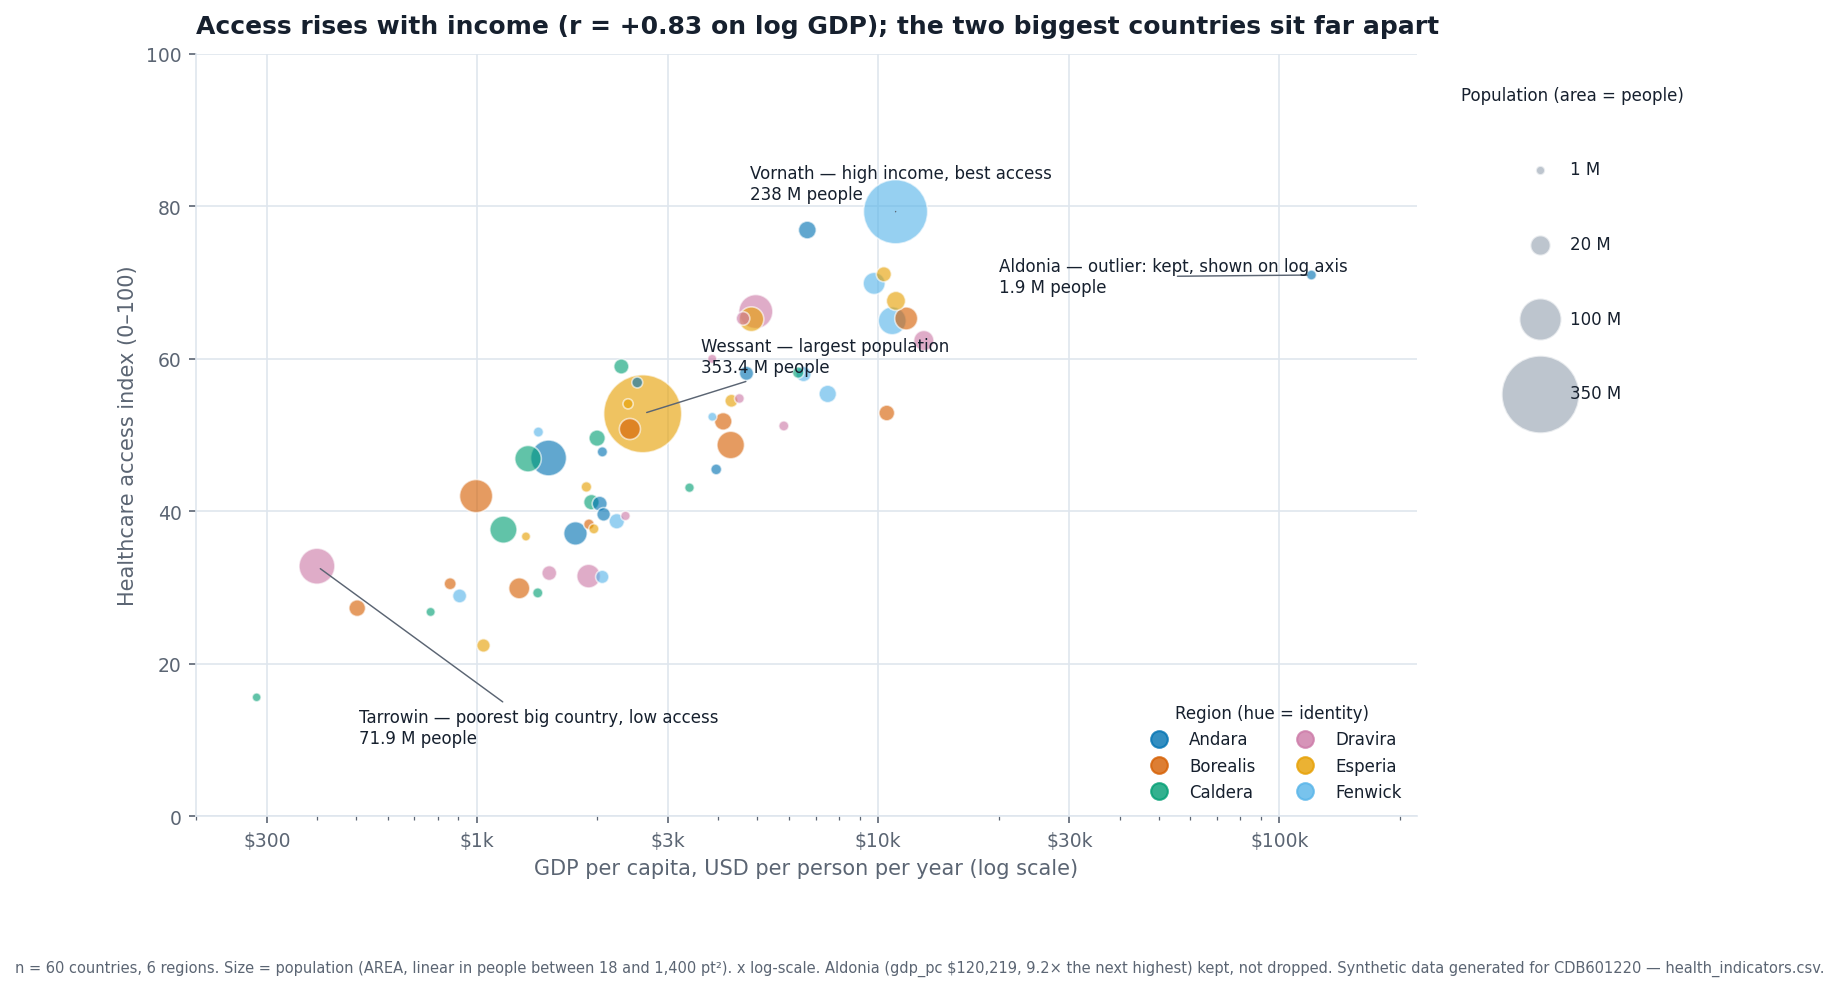

In [4]:
regions = sorted(hi.region.unique())
col = dict(zip(regions, HUES))

fig, ax = plt.subplots(figsize=(10.5, 6.6))
order = np.argsort(-pop)                  # big marks first so small ones stay visible on top
ax.scatter(hi.gdp_pc.iloc[order], hi.healthcare_access.iloc[order], s=s[order],
           c=[col[r] for r in hi.region.iloc[order]], alpha=0.62,
           edgecolor="white", linewidth=0.8, zorder=3)
ax.set_xscale("log")
ax.set_xlim(200, 2.2e5); ax.set_ylim(0, 100)
ax.set_xticks([300, 1000, 3000, 10000, 30000, 100000])
ax.set_xticklabels(["$300", "$1k", "$3k", "$10k", "$30k", "$100k"])
ax.set_xlabel("GDP per capita, USD per person per year (log scale)")
ax.set_ylabel("Healthcare access index (0–100)")

# --- direct labels for the four countries I will talk about
talk = {"Wessant":  ("largest population", (28, 20)),
        "Vornath":  ("high income, best access", (-70, 6)),
        "Tarrowin": ("poorest big country, low access", (20, -85)),
        "Aldonia":  ("outlier: kept, shown on log axis", (-150, -8))}
for name, (why, off) in talk.items():
    r = hi[hi.country == name].iloc[0]
    ax.annotate(f"{name} — {why}\n{r.pop_m:g} M people", (r.gdp_pc, r.healthcare_access),
                xytext=off, textcoords="offset points", fontsize=8, color=PAL["ink"],
                arrowprops=dict(arrowstyle="-", color=PAL["ink_soft"], lw=0.7), zorder=6)

# --- hue legend (identity)
from matplotlib.lines import Line2D
h1 = [Line2D([], [], marker="o", ls="", markersize=8, color=col[r], alpha=0.8, label=r) for r in regions]
leg1 = ax.legend(handles=h1, title="Region (hue = identity)", loc="lower right",
                 fontsize=8, title_fontsize=8, ncol=2)
ax.add_artist(leg1)
# --- size legend: three reference circles with REAL populations (slide 11)
refs = np.array([1, 20, 100, 350])
hs = [ax.scatter([], [], s=area_pt2(v), color=PAL["muted"], alpha=0.65, edgecolor="white",
                 label=f"{v:g} M") for v in refs]
ax.legend(handles=hs, title="Population (area = people)", loc="upper left", bbox_to_anchor=(1.01, 1.0),
          labelspacing=3.4, borderpad=1.4, fontsize=8, title_fontsize=8, scatterpoints=1)

r_ = hi.gdp_pc.apply(np.log10).corr(hi.healthcare_access)
ax.set_title(f"Access rises with income (r = {r_:+.2f} on log GDP); the two biggest countries sit far apart", loc="left")
note = ("n = 60 countries, 6 regions. Size = population (AREA, linear in people between 18 and 1,400 pt²). "
        "x log-scale. Aldonia (gdp_pc $120,219, 9.2× the next highest) kept, not dropped. "
        "Synthetic data generated for CDB601220 — health_indicators.csv.")
g.save_fig(fig, FIG + "partD_bubble.png", note=note)
plt.show()

## Declared decisions (also printed on the figure)

* **Area, not radius** — I pass area in pt² to `ax.scatter(s=...)`; the assert above shows radius² = area. Diameter ratio ≈ 8.8×, not the 589× that the raw population range might suggest.
* **Size legend** — four reference circles labelled with real populations (1, 20, 100, 350 M), drawn with the same function as the data.
* **Outlier** — Aldonia ($120,219) is real-looking (small, urban, high access); a log axis absorbs it, so I kept it and said so on the figure.
* **Labels** — four countries labelled directly instead of a sixty-row legend.
* Colour: six Okabe–Ito hues, CVD ΔE printed above.